# Rossmann Store Sales — Data Exploration
**Project:** Sales Forecasting and Promotion Optimization for Retail
**Author:** Yahya Alkayem · University of Birmingham Dubai · Final Year Project

**Goal of this notebook:** understand the dataset, check its quality, and show that it supports the two parts of the project:
1. **Forecasting** daily sales per store
2. **Optimizing** when and where to run promotions

**Source:** [Kaggle — Rossmann Store Sales](https://www.kaggle.com/competitions/rossmann-store-sales) (real data from 1,115 Rossmann drugstores in Germany)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

train = pd.read_csv("../data/train.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
store = pd.read_csv("../data/store.csv")
df = train.merge(store, on="Store", how="left")

## 1. What's in the data

In [2]:
print(f"train.csv : {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"store.csv : {store.shape[0]:,} rows x {store.shape[1]} columns")
print(f"Stores    : {train.Store.nunique():,}")
print(f"Date range: {train.Date.min().date()} to {train.Date.max().date()} ({train.Date.nunique()} days)")
df.head()

train.csv : 1,017,209 rows x 9 columns
store.csv : 1,115 rows x 10 columns
Stores    : 1,115
Date range: 2013-01-01 to 2015-07-31 (942 days)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


### Column dictionary
| Column | Meaning | Used for |
|---|---|---|
| `Sales` | Daily turnover (target) | Forecasting target |
| `Customers` | Number of customers that day | Analysis only (not known in advance) |
| `Open` | Store open (1) or closed (0) | Filtering |
| `Promo` | Store running a daily promotion | **Optimization decision variable** |
| `Promo2` / `PromoInterval` | Long-running recurring promotion | Feature |
| `StateHoliday` / `SchoolHoliday` | Holiday indicators | Feature |
| `StoreType` / `Assortment` | Store format and product range (a/b/c/d) | Segmentation |
| `CompetitionDistance` | Distance to nearest competitor (m) | Feature |
| `DayOfWeek`, `Date` | Calendar | Seasonality features |

## 2. Data quality

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["% of rows"] = (missing["missing"] / len(df) * 100).round(1)
missing

,missing,% of rows
CompetitionDistance,2642,0.3
CompetitionOpenSinceMonth,323348,31.8
CompetitionOpenSinceYear,323348,31.8
Promo2SinceWeek,508031,49.9
Promo2SinceYear,508031,49.9
PromoInterval,508031,49.9


In [4]:
closed = (df.Open == 0).sum()
zero_open = ((df.Open == 1) & (df.Sales == 0)).sum()
print(f"Closed-store days      : {closed:,} ({closed/len(df):.1%}) -> sales are always 0, will be excluded")
print(f"Open but zero sales    : {zero_open} -> negligible, likely data errors")
print(f"Duplicate rows         : {df.duplicated().sum()}")

Closed-store days      : 172,817 (17.0%) -> sales are always 0, will be excluded
Open but zero sales    : 54 -> negligible, likely data errors


Duplicate rows         : 0


**Takeaway:** the sales data itself is complete — no missing values in `train.csv`. Missing values only appear in competitor/Promo2 details in `store.csv`, and mostly mean "no competitor info" or "not in Promo2", so they're easy to handle.

In [5]:
open_df = df[(df.Open == 1) & (df.Sales > 0)].copy()
open_df["Year"] = open_df.Date.dt.year
open_df["Month"] = open_df.Date.dt.month
print(f"Rows used for analysis: {len(open_df):,}")
open_df.Sales.describe().round(0)

Rows used for analysis: 844,338


count    844338.0
mean       6956.0
std        3104.0
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: Sales, dtype: float64

## 3. Sales over time

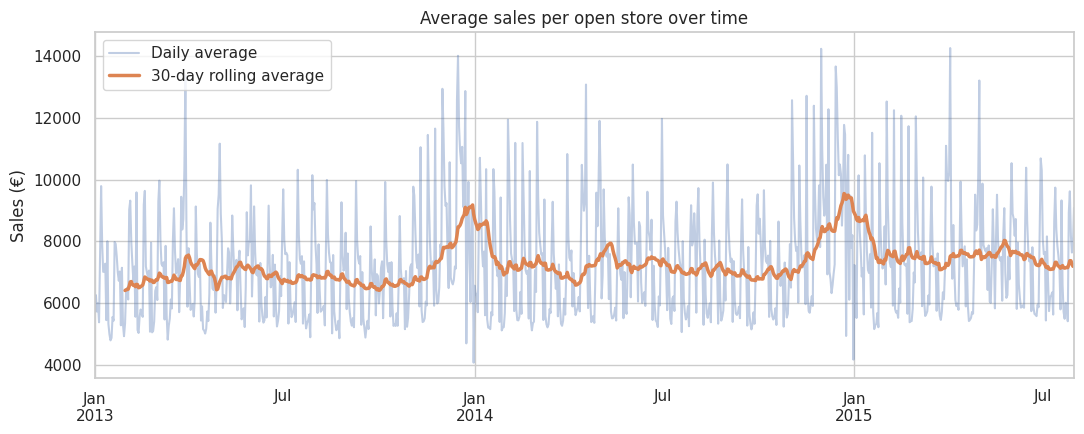

In [6]:
daily = open_df.groupby("Date").Sales.mean()
ax = daily.plot(alpha=0.35, label="Daily average")
daily.rolling(30).mean().plot(ax=ax, linewidth=2.5, label="30-day rolling average")
ax.set_title("Average sales per open store over time")
ax.set_ylabel("Sales (€)"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.savefig("../figures/sales_over_time.png", dpi=120); plt.show()

**Takeaway:** clear yearly seasonality with a strong December (Christmas) spike, and a repeating weekly pattern — good structure for a forecasting model to learn.

## 4. Impact of promotions (the core of the project)

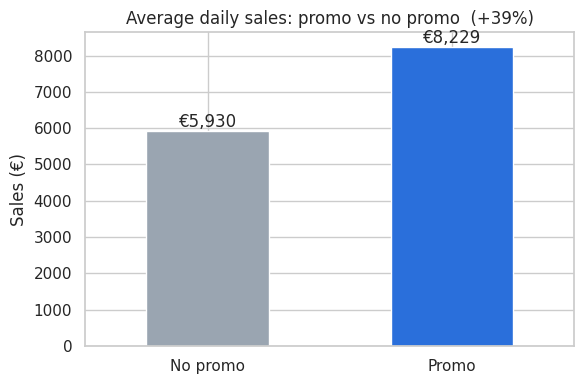

In [7]:
promo = open_df.groupby("Promo").Sales.mean()
uplift = promo[1] / promo[0] - 1
ax = promo.rename({0: "No promo", 1: "Promo"}).plot(kind="bar", color=["#9aa5b1", "#2a6fdb"], rot=0, figsize=(6, 4))
ax.set_title(f"Average daily sales: promo vs no promo  (+{uplift:.0%})")
ax.set_ylabel("Sales (€)"); ax.set_xlabel("")
for i, v in enumerate(promo): ax.text(i, v, f"€{v:,.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig("../figures/promo_uplift.png", dpi=120); plt.show()

In [8]:
by_type = open_df.groupby(["StoreType", "Promo"]).Sales.mean().unstack()
by_type.columns = ["No promo", "Promo"]
by_type["Uplift %"] = ((by_type["Promo"] / by_type["No promo"] - 1) * 100).round(1)
by_type.round(0)

,No promo,Promo,Uplift %
StoreType,,,
a,5809.0,8305.0,43.0
b,9568.0,11312.0,18.0
c,6029.0,8043.0,33.0
d,5855.0,8018.0,37.0


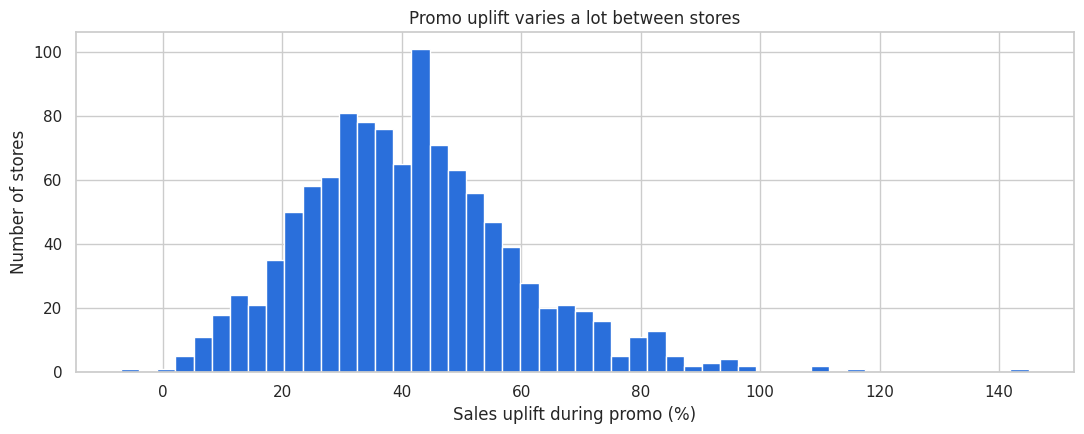

Uplift ranges from -7% to 145% (median 41%)


In [9]:
store_uplift = open_df.groupby(["Store", "Promo"]).Sales.mean().unstack()
store_uplift = (store_uplift[1] / store_uplift[0] - 1) * 100
ax = store_uplift.plot(kind="hist", bins=50, color="#2a6fdb")
ax.set_title("Promo uplift varies a lot between stores")
ax.set_xlabel("Sales uplift during promo (%)"); ax.set_ylabel("Number of stores")
plt.tight_layout(); plt.savefig("../figures/promo_uplift_by_store.png", dpi=120); plt.show()
print(f"Uplift ranges from {store_uplift.min():.0f}% to {store_uplift.max():.0f}% (median {store_uplift.median():.0f}%)")

**Takeaway:** promotions increase sales substantially on average, but **the effect is very different from store to store**. This is exactly why optimization is worthwhile: if promo days are limited, they should go to the stores and days where they generate the most extra sales.

## 5. Weekly pattern and promo timing

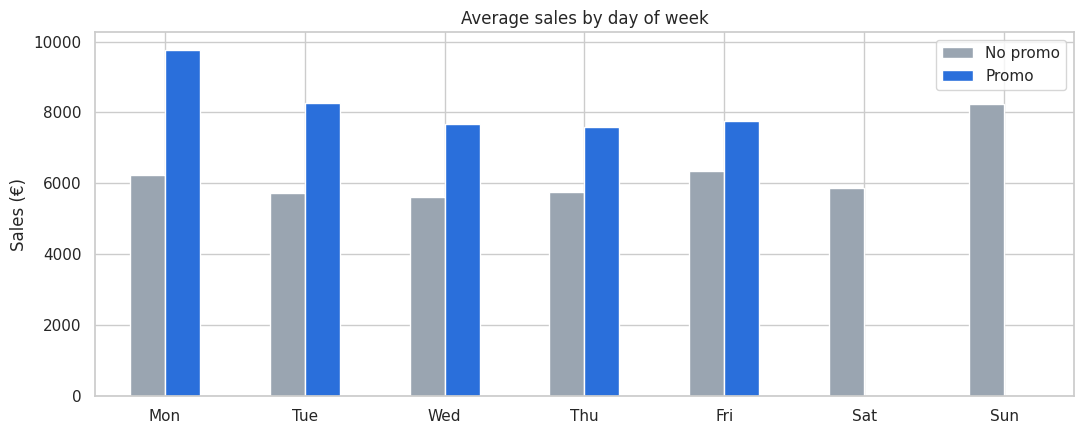

In [10]:
dow = open_df.groupby(["DayOfWeek", "Promo"]).Sales.mean().unstack()
dow.columns = ["No promo", "Promo"]
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(dow)]
ax = dow.plot(kind="bar", rot=0, color=["#9aa5b1", "#2a6fdb"])
ax.set_title("Average sales by day of week")
ax.set_ylabel("Sales (€)")
plt.tight_layout(); plt.savefig("../figures/day_of_week.png", dpi=120); plt.show()

**Takeaway:** Monday is the strongest regular trading day, and promos only run Monday–Friday (Sunday looks high only because very few stores open on Sundays). Timing matters — another input for the optimization.

## 6. Store types, holidays and competition

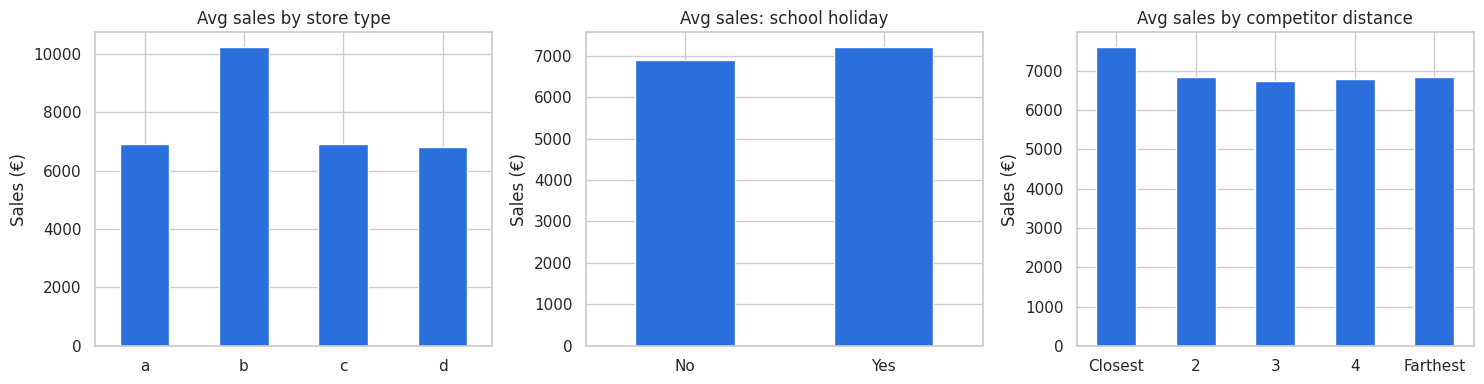

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
open_df.groupby("StoreType").Sales.mean().plot(kind="bar", ax=axes[0], rot=0, color="#2a6fdb", title="Avg sales by store type")
open_df.groupby("SchoolHoliday").Sales.mean().rename({0: "No", 1: "Yes"}).plot(kind="bar", ax=axes[1], rot=0, color="#2a6fdb", title="Avg sales: school holiday")
comp = open_df.dropna(subset=["CompetitionDistance"]).copy()
comp["CompBand"] = pd.qcut(comp.CompetitionDistance, 5, labels=["Closest", "2", "3", "4", "Farthest"])
comp.groupby("CompBand", observed=True).Sales.mean().plot(kind="bar", ax=axes[2], rot=0, color="#2a6fdb", title="Avg sales by competitor distance")
for a in axes: a.set_xlabel(""); a.set_ylabel("Sales (€)")
plt.tight_layout(); plt.savefig("../figures/store_factors.png", dpi=120); plt.show()

## 7. Summary — why this dataset fits the project

| Requirement | Supported by the data? |
|---|---|
| Large, real, business dataset | ✅ ~1M daily records, 1,115 real stores, 2.5 years |
| Clean enough to model | ✅ No missing sales; only minor gaps in store metadata |
| Forecasting target | ✅ `Sales` per store per day |
| Seasonality / calendar effects | ✅ Weekly, yearly and holiday patterns are clear |
| **Optimization lever** | ✅ `Promo` — a controllable decision with a large, store-dependent effect |

### Proposed next steps
1. **Feature engineering** — calendar, holiday, competition and promo-history features
2. **Forecasting models** — naive baseline → linear regression → gradient boosting (LightGBM/XGBoost), evaluated with RMSPE on a time-based split
3. **Promo optimization** — use the forecasting model to estimate each store's sales *with* vs *without* a promo, then allocate a limited promo budget to maximize total sales (greedy / linear programming)
4. **Business output** — recommendations and a simple dashboard for a retail manager